# Blue Agent v2 - retrained against the tougher Red Agent v2

**The adaptive loop, round 2:**
1. Round 1: Blue Agent v1 caught 100% of the v1 attacks (99.2% 5-class accuracy, AUC 1.0).
2. Red Agent v2 (`red_agent/RedAgent_Attacks_v2.ipynb`) made the **same FGSM and PGD** stealthier: mixed strength (`low_eps`), `l2` noise, and **detector-aware** (`adaptive`) attacks that also try to make the Blue Agent v1 say "genuine".
3. **This notebook:** train Blue Agent v2 on the v1 data **plus** the v2 attacks, then compare v1 and v2 on the same held-out test images.

| what stays the same as v1 | what changes |
|---|---|
| 5 classes (genuine, gan, fgsm, pgd, gan_adv) + `suspicious` | 1,500 extra attack images from Red Agent v2 (fgsm / pgd / gan_adv, each 1/3 per technique) |
| ResNet-18 pretrained on ImageNet, same training settings | **class weights** in the loss: the attack classes now have 1,000 images each, genuine and gan 500 |
| anti-shortcut degradation of genuine faces, flip-only augmentation | |
| **the exact v1 person split** - every person and every v1 image keeps its v1 split, v2 attacks of a person follow that person | v2 `gan_adv` faces (new faces) are split 70/15/15 per technique |

Because the split is identical, the **v1 test images are the same** for both models, and no v2 attack of a test person is ever used for training.

**Honest caveat:** the `adaptive` attacks were optimised against Blue Agent **v1**. For v1 they are a white-box adaptive attack; for v2 they are known attack examples it has trained on. A new adaptive attack against v2 would be round 3.

Needs (inside `celeba/`): `red_agent_samples/` (v1), `red_agent_samples_v2/` (v2), `blue_agent/split.csv` + `blue_agent/blue_agent_resnet18.pth` (Blue Agent v1). Output: `celeba/blue_agent_v2/`.

### 0. setup

In [3]:
import os, time, copy, random, shutil
os.chdir("/workspace")
print("working directory:", os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFilter
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

working directory: /workspace
device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition MIG 1g.24gb
torch 2.8.0+cu128 | torchvision 0.23.0+cu128


In [4]:
BASE = "./celeba"
V1_DIR = os.path.join(BASE, "red_agent_samples")
V2_DIR = os.path.join(BASE, "red_agent_samples_v2")
BLUE_V1_PATH = os.path.join(BASE, "blue_agent", "blue_agent_resnet18.pth")
SPLIT_V1_PATH = os.path.join(BASE, "blue_agent", "split.csv")
OUT_DIR = os.path.join(BASE, "blue_agent_v2")
for p in [V1_DIR, V2_DIR, BLUE_V1_PATH, SPLIT_V1_PATH]:
    assert os.path.exists(p), f"missing: {p}"
os.makedirs(OUT_DIR, exist_ok=True)

CLASSES = ["genuine", "gan", "fgsm", "pgd", "gan_adv"]
CLS_IDX = {c: i for i, c in enumerate(CLASSES)}

EPOCHS = 20
BATCH = 64
LR = 3e-4
WEIGHT_DECAY = 1e-4
DEGRADE_P = 0.3        # share of genuine training faces randomly downscaled/blurred (anti-shortcut)
KEEP_CORRECT = 0.95    # suspicious threshold: keep 95% of correct validation predictions
NUM_WORKERS = min(8, os.cpu_count() or 2)
IMG_SIZE = 160

### 1. load the v1 + v2 datasets
v1: 2,500 images (5 classes x 500). v2: 1,500 tougher attacks (fgsm / pgd / gan_adv x 500) with a `technique` column (`low_eps`, `l2`, `adaptive`). The v1 rows get `technique = v1`.

In [5]:
l1 = pd.read_csv(os.path.join(V1_DIR, "labels.csv")); l1["source"] = "v1"; l1["technique"] = "v1"
l1["path"] = [os.path.join(V1_DIR, c, f) for c, f in zip(l1["category"], l1["file_name"])]
l2 = pd.read_csv(os.path.join(V2_DIR, "labels.csv")); l2["source"] = "v2"
l2["path"] = [os.path.join(V2_DIR, c, f) for c, f in zip(l2["category"], l2["file_name"])]
labels = pd.concat([l1, l2], ignore_index=True)
labels["label"] = labels["category"].map(CLS_IDX)
missing = [p for p in labels["path"] if not os.path.exists(p)]
assert not missing, f"{len(missing)} image files missing, e.g. {missing[:3]}"
assert labels["label"].notna().all(), "unknown category in labels.csv"

sizes = {Image.open(p).size for p in labels["path"].sample(min(50, len(labels)), random_state=SEED)}
print("image sizes:", sizes)
print(pd.crosstab(labels["category"], labels["technique"]).reindex(index=CLASSES).fillna(0).astype(int).to_string())

image sizes: {(160, 160)}
technique  adaptive   l2  low_eps   v1
category                              
genuine           0    0        0  500
gan               0    0        0  500
fgsm            166  167      167  500
pgd             166  167      167  500
gan_adv         166  167      167  500


### 2. split: reuse the v1 split exactly (no leakage)
- every **v1 image** keeps the split it had in Blue Agent v1 (`blue_agent/split.csv`) - so the v1 test images are identical for both models.
- every **v2 person-based attack** (`fgsm`, `pgd`) goes to the split of its **person** - an attacked copy of a test person can never be in training.
- **v2 `gan_adv`**: new GAN faces that belong to nobody, split 70 / 15 / 15 per technique.

In [6]:
rng = np.random.default_rng(SEED)

def cut(n):
    n_tr = int(round(0.70 * n)); n_va = int(round(0.15 * n))
    return np.array(["train"] * n_tr + ["val"] * n_va + ["test"] * (n - n_tr - n_va))

split_v1 = pd.read_csv(SPLIT_V1_PATH)
key = lambda df: df["category"] + "/" + df["file_name"]
v1_split = dict(zip(key(split_v1), split_v1["split"]))
id_split = split_v1[split_v1["category"].isin(["genuine", "fgsm", "pgd"])].drop_duplicates("identity").set_index("identity")["split"]

labels["split"] = ""
is_v1 = labels["source"] == "v1"
labels.loc[is_v1, "split"] = key(labels[is_v1]).map(v1_split)
person = labels["category"].isin(["genuine", "fgsm", "pgd"])
labels.loc[~is_v1 & person, "split"] = labels.loc[~is_v1 & person, "identity"].map(id_split)
for t in sorted(labels.loc[~is_v1 & ~person, "technique"].unique()):
    idx = rng.permutation(labels.index[~is_v1 & ~person & (labels["technique"] == t)].to_numpy())
    labels.loc[idx, "split"] = cut(len(idx))
assert labels["split"].isin(["train", "val", "test"]).all(), "some images got no split"

# leakage checks
per_id = labels[person].groupby("identity")["split"].nunique()
assert (per_id == 1).all(), "an identity appears in more than one split"
per_file = labels[person].groupby("file_name")["split"].nunique()
assert (per_file == 1).all(), "a source face appears in more than one split"
print("leakage check passed: v1 split reused, every person and every source face is in exactly one split\n")

ct = pd.crosstab([labels["category"], labels["source"]], labels["split"]).reindex(columns=["train", "val", "test"])
print(ct.to_string())
labels[["category", "file_name", "identity", "attack", "source", "technique", "split"]].to_csv(os.path.join(OUT_DIR, "split.csv"), index=False)

leakage check passed: v1 split reused, every person and every source face is in exactly one split

split            train  val  test
category source                  
fgsm     v1        355   72    73
         v2        355   72    73
gan      v1        350   75    75
gan_adv  v1        350   75    75
         v2        350   75    75
genuine  v1        355   72    73
pgd      v1        355   72    73
         v2        355   72    73


### 3. dataset, augmentation and the anti-shortcut trick
- images are used at their saved 160x160 PNG resolution - **no resize**, so the 8/255 adversarial noise is untouched.
- training only: horizontal flip for every class; for ~30% of **genuine** faces, either downscale to 64x64 and back (the same resolution loss our GAN faces have) or a light Gaussian blur. They stay labelled `genuine`, so "blurry" alone can no longer mean "fake".
- normalised with the ImageNet mean/std, because the backbone was pretrained on ImageNet.

train 2825 | val 585 | test 590


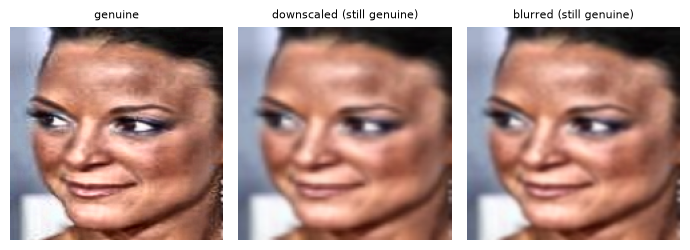

In [7]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def to_tensor(img):
    a = torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.0).permute(2, 0, 1)
    return (a - MEAN) / STD

def degrade(img, mode=None, radius=None):
    # mode "down": 160 -> 64 -> 160 (GAN-like resolution loss); mode "blur": Gaussian blur
    mode = mode or random.choice(["down", "blur"])
    if mode == "down":
        return img.resize((64, 64), Image.BILINEAR).resize(img.size, Image.BILINEAR)
    return img.filter(ImageFilter.GaussianBlur(radius if radius is not None else random.uniform(0.6, 1.5)))

class FaceSet(Dataset):
    def __init__(self, df, train=False):
        self.paths = df["path"].tolist()
        self.labels = df["label"].astype(int).tolist()
        self.train = train

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        y = self.labels[i]
        if self.train:
            if y == CLS_IDX["genuine"] and random.random() < DEGRADE_P:
                img = degrade(img)
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
        return to_tensor(img), y

df_tr, df_va, df_te = (labels[labels["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"])
loader_kw = dict(batch_size=BATCH, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
dl_tr = DataLoader(FaceSet(df_tr, train=True), shuffle=True, drop_last=False, **loader_kw)
dl_va = DataLoader(FaceSet(df_va), shuffle=False, **loader_kw)
dl_te = DataLoader(FaceSet(df_te), shuffle=False, **loader_kw)
print(f"train {len(df_tr)} | val {len(df_va)} | test {len(df_te)}")

# what the anti-shortcut augmentation looks like
ex = Image.open(df_tr[df_tr["category"] == "genuine"]["path"].iloc[0]).convert("RGB")
fig, ax = plt.subplots(1, 3, figsize=(7, 2.6))
for a, (t, im) in zip(ax, [("genuine", ex), ("downscaled (still genuine)", degrade(ex, "down")),
                           ("blurred (still genuine)", degrade(ex, "blur", 1.2))]):
    a.imshow(im); a.set_title(t, fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

### 4. model: ResNet-18 pretrained on ImageNet
ImageNet pretraining gives the network ready-made edge and texture filters, which matters with only ~1,750 training images. The 1000-class ImageNet layer is replaced with a 5-class layer; the whole network is then fine-tuned.

In [8]:
model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
model = model.to(device)
print(f"ResNet-18 | parameters: {sum(p.numel() for p in model.parameters()):,} | outputs: {CLASSES}")

ResNet-18 | parameters: 11,179,077 | outputs: ['genuine', 'gan', 'fgsm', 'pgd', 'gan_adv']


### 5. training
AdamW + cosine learning-rate decay, class-weighted cross-entropy loss. After every epoch the model is scored on the **validation** set; the epoch with the best validation macro-F1 is kept. The test set is not touched until section 7.

In [9]:
# class weights: attack classes now have 1,000 images each, genuine and gan 500
counts = df_tr["label"].value_counts().reindex(range(len(CLASSES)), fill_value=0).to_numpy()
class_w = torch.tensor(counts.sum() / (len(CLASSES) * np.maximum(counts, 1)), dtype=torch.float32)
print("training images per class:", dict(zip(CLASSES, counts)), "| loss weights:", dict(zip(CLASSES, class_w.numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=class_w.to(device))
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

@torch.no_grad()
def predict_loader(dl):
    model.eval()
    probs, ys, loss_sum = [], [], 0.0
    for x, y in dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(x)
        loss_sum += criterion(out, y).item() * len(y)
        probs.append(torch.softmax(out, 1).cpu()); ys.append(y.cpu())
    probs, ys = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    return probs, ys, loss_sum / len(ys)

history, best_f1, best_state, best_epoch = [], -1.0, None, 0
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    tr_loss, tr_correct, n = 0.0, 0, 0
    for x, y in dl_tr:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * len(y); tr_correct += (out.argmax(1) == y).sum().item(); n += len(y)
    scheduler.step()

    p_va, y_va, va_loss = predict_loader(dl_va)
    va_pred = p_va.argmax(1)
    va_acc, va_f1 = accuracy_score(y_va, va_pred), f1_score(y_va, va_pred, average="macro")
    history.append(dict(epoch=epoch, train_loss=tr_loss / n, train_acc=tr_correct / n,
                        val_loss=va_loss, val_acc=va_acc, val_macro_f1=va_f1))
    mark = ""
    if va_f1 > best_f1:
        best_f1, best_epoch, best_state = va_f1, epoch, copy.deepcopy(model.state_dict()); mark = "  <- best"
    print(f"epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss / n:.3f} acc {tr_correct / n:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} macro-F1 {va_f1:.3f}{mark}")

model.load_state_dict(best_state)
print(f"\ntraining done in {time.time() - t0:.0f}s | best epoch {best_epoch} (val macro-F1 {best_f1:.3f})")
hist = pd.DataFrame(history)
hist.to_csv(os.path.join(OUT_DIR, "history.csv"), index=False)

training images per class: {'genuine': np.int64(355), 'gan': np.int64(350), 'fgsm': np.int64(710), 'pgd': np.int64(710), 'gan_adv': np.int64(700)} | loss weights: {'genuine': np.float32(1.59), 'gan': np.float32(1.61), 'fgsm': np.float32(0.8), 'pgd': np.float32(0.8), 'gan_adv': np.float32(0.81)}
epoch  1/20 | train loss 0.662 acc 0.734 | val loss 0.701 acc 0.766 macro-F1 0.765  <- best
epoch  2/20 | train loss 0.369 acc 0.844 | val loss 1.207 acc 0.703 macro-F1 0.701
epoch  3/20 | train loss 0.304 acc 0.866 | val loss 0.293 acc 0.875 macro-F1 0.870  <- best
epoch  4/20 | train loss 0.288 acc 0.876 | val loss 0.603 acc 0.773 macro-F1 0.768
epoch  5/20 | train loss 0.223 acc 0.903 | val loss 0.312 acc 0.858 macro-F1 0.855
epoch  6/20 | train loss 0.235 acc 0.899 | val loss 0.731 acc 0.824 macro-F1 0.821
epoch  7/20 | train loss 0.182 acc 0.918 | val loss 0.250 acc 0.874 macro-F1 0.867
epoch  8/20 | train loss 0.206 acc 0.905 | val loss 0.606 acc 0.745 macro-F1 0.724
epoch  9/20 | train lo

### 6. training curves (overfitting check)
Train accuracy near 1.0 with validation clearly lower and validation loss rising = overfitting. The saved model is the best-validation epoch, not the last one.

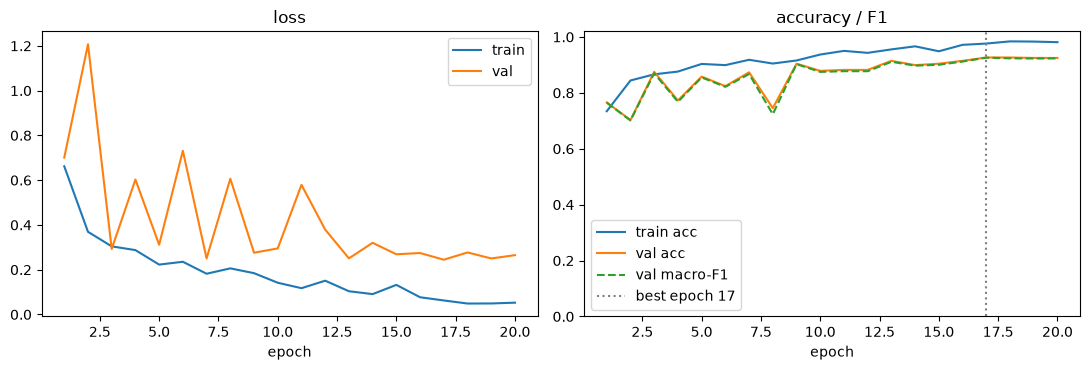

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(hist["epoch"], hist["train_loss"], label="train"); ax[0].plot(hist["epoch"], hist["val_loss"], label="val")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["epoch"], hist["train_acc"], label="train acc"); ax[1].plot(hist["epoch"], hist["val_acc"], label="val acc")
ax[1].plot(hist["epoch"], hist["val_macro_f1"], "--", label="val macro-F1")
ax[1].axvline(best_epoch, color="gray", ls=":", label=f"best epoch {best_epoch}")
ax[1].set_title("accuracy / F1"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1.02); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=120); plt.show()

### 7. test results (images never seen in training or model selection)
- **precision**: when the Blue Agent says "PGD", how often is it really PGD
- **recall**: of all real PGD images, how many it caught
- **F1**: balance of the two

TEST accuracy: 0.876 | macro-F1: 0.874 | images: 590

              precision    recall  f1-score   support

     genuine      0.693     0.959     0.805        73
         gan      0.862     1.000     0.926        75
        fgsm      0.876     0.822     0.848       146
         pgd      0.927     0.781     0.848       146
     gan_adv      0.972     0.920     0.945       150

    accuracy                          0.876       590
   macro avg      0.866     0.896     0.874       590
weighted avg      0.889     0.876     0.877       590

accuracy on v1 test images: 0.976 (369 images)
accuracy on v2 test images: 0.710 (221 images)


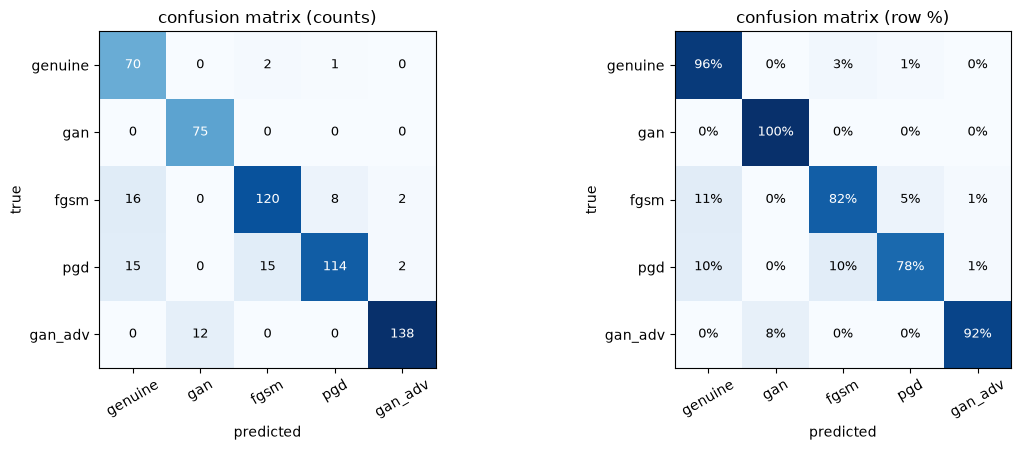

In [11]:
p_te, y_te, te_loss = predict_loader(dl_te)
pred_te = p_te.argmax(1)
test_acc = accuracy_score(y_te, pred_te)
test_f1 = f1_score(y_te, pred_te, average="macro")
print(f"TEST accuracy: {test_acc:.3f} | macro-F1: {test_f1:.3f} | images: {len(y_te)}\n")
report = classification_report(y_te, pred_te, labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0)
print(report)
for src in ["v1", "v2"]:
    m = (df_te["source"] == src).to_numpy()
    print(f"accuracy on {src} test images: {accuracy_score(y_te[m], pred_te[m]):.3f} ({m.sum()} images)")

cm = confusion_matrix(y_te, pred_te, labels=range(len(CLASSES)))
cm_norm = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, m, title, fmt in [(ax[0], cm, "confusion matrix (counts)", "d"), (ax[1], cm_norm, "confusion matrix (row %)", ".0%")]:
    a.imshow(m, cmap="Blues")
    a.set_xticks(range(len(CLASSES)), CLASSES, rotation=30); a.set_yticks(range(len(CLASSES)), CLASSES)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(title)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            v = m[i, j]
            a.text(j, i, format(v, fmt), ha="center", va="center", fontsize=9,
                   color="white" if (cm_norm[i, j] > 0.5) else "black")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=120); plt.show()

### 8. genuine vs attack - the number the risk engine needs
The risk engine does not need to know *which* attack it is, only *how likely the image is manipulated*:

`attack probability = 1 - P(genuine)`

- **ROC AUC**: 1.0 = attacks and genuine faces perfectly separated, 0.5 = guessing.
- at the default cut-off (attack probability >= 0.5): how many of each attack type are caught, and how many genuine users are wrongly flagged (false alarms).

genuine vs attack ROC AUC: 0.9864
(for genuine, 'flagged_as_attack' = false-alarm rate; for the others it is the detection rate)

                          category  images flagged_as_attack  mean_attack_prob
                           genuine      73              5.5%             0.080
                               gan      75            100.0%             0.999
                              fgsm     146             90.4%             0.905
                               pgd     146             91.1%             0.909
                           gan_adv     150            100.0%             1.000
                    gan_adv (fgsm)      33            100.0%             1.000
                     gan_adv (pgd)      42            100.0%             1.000
   v2 low_eps (all attack classes)      67             97.0%             0.943
        v2 l2 (all attack classes)      78             69.2%             0.714
  v2 adaptive (all attack classes)      76             98.7%             0.987


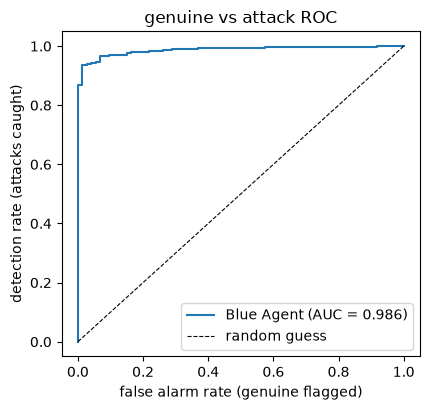

In [12]:
p_attack = 1 - p_te[:, CLS_IDX["genuine"]]
is_attack = (y_te != CLS_IDX["genuine"]).astype(int)
auc = roc_auc_score(is_attack, p_attack) if len(np.unique(is_attack)) == 2 else float("nan")
flag = p_attack >= 0.5

rows = []
for cat in CLASSES:
    m = (df_te["category"] == cat).to_numpy()
    rows.append(dict(category=cat, images=int(m.sum()),
                     flagged_as_attack=f"{flag[m].mean():.1%}" if m.any() else "-",
                     mean_attack_prob=round(float(p_attack[m].mean()), 3) if m.any() else np.nan))
for att in ["fgsm", "pgd"]:
    m = ((df_te["category"] == "gan_adv") & (df_te["attack"] == att) & (df_te["source"] == "v1")).to_numpy()
    rows.append(dict(category=f"  gan_adv ({att})", images=int(m.sum()),
                     flagged_as_attack=f"{flag[m].mean():.1%}" if m.any() else "-",
                     mean_attack_prob=round(float(p_attack[m].mean()), 3) if m.any() else np.nan))
for t in ["low_eps", "l2", "adaptive"]:
    m = (df_te["technique"] == t).to_numpy()
    rows.append(dict(category=f"  v2 {t} (all attack classes)", images=int(m.sum()),
                     flagged_as_attack=f"{flag[m].mean():.1%}" if m.any() else "-",
                     mean_attack_prob=round(float(p_attack[m].mean()), 3) if m.any() else np.nan))
det = pd.DataFrame(rows)
print(f"genuine vs attack ROC AUC: {auc:.4f}")
print("(for genuine, 'flagged_as_attack' = false-alarm rate; for the others it is the detection rate)\n")
print(det.to_string(index=False))

fpr, tpr, _ = roc_curve(is_attack, p_attack)
plt.figure(figsize=(4.4, 4.2))
plt.plot(fpr, tpr, label=f"Blue Agent (AUC = {auc:.3f})"); plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random guess")
plt.xlabel("false alarm rate (genuine flagged)"); plt.ylabel("detection rate (attacks caught)")
plt.title("genuine vs attack ROC"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "roc_genuine_vs_attack.png"), dpi=120); plt.show()

### 8b. Blue Agent v1 vs v2 on the same test images
Both models are scored on exactly the same held-out test images (neither trained on them):
- `5-class accuracy`: v1 test images and v2 test images separately
- `detection rate`: share of attacks flagged (attack probability >= 0.5), per v2 technique
- `false alarms`: genuine test faces flagged as attacks
- **`full bypass`**: the attack fools FaceNet (measured in the Red Agent v2 notebook) **and** the Blue Agent does not flag it - the attacker gets through both layers

In [13]:
ck1 = torch.load(BLUE_V1_PATH, map_location=device, weights_only=True)
blue_v1 = torchvision.models.resnet18(weights=None)
blue_v1.fc = nn.Linear(blue_v1.fc.in_features, len(ck1["classes"]))
blue_v1.load_state_dict(ck1["state_dict"])
blue_v1 = blue_v1.to(device).eval()
assert ck1["classes"] == CLASSES

@torch.no_grad()
def probs_of(net, dl):
    net.eval()
    return torch.cat([torch.softmax(net(x.to(device)), 1).cpu() for x, _ in dl]).numpy()

P = {"Blue v1": probs_of(blue_v1, dl_te), "Blue v2": p_te}
fooled = df_te["face_fooled"].eq(True).to_numpy()      # NaN for v1 rows -> False
rows = []
for name, pr in P.items():
    pa = 1 - pr[:, CLS_IDX["genuine"]]; fl = pa >= 0.5; pc = pr.argmax(1)
    r = {"model": name}
    for src in ["v1", "v2"]:
        m = (df_te["source"] == src).to_numpy()
        r[f"5-class acc ({src} test)"] = accuracy_score(y_te[m], pc[m]) if m.any() else np.nan
    g = (df_te["category"] == "genuine").to_numpy()
    r["false alarms (genuine)"] = fl[g].mean()
    for t in ["v1", "low_eps", "l2", "adaptive"]:
        m = ((df_te["technique"] == t) & (df_te["category"] != "genuine") & (df_te["category"] != "gan")).to_numpy() if t == "v1" \
            else (df_te["technique"] == t).to_numpy()
        r[f"detected: {t}"] = fl[m].mean() if m.any() else np.nan
    v2m = (df_te["source"] == "v2").to_numpy()
    r["full bypass (v2 attacks)"] = (fooled[v2m] & ~fl[v2m]).mean() if v2m.any() else np.nan
    rows.append(r)
comparison = pd.DataFrame(rows).set_index("model").T
print(comparison.round(3).to_string())
print("\n'detected: v1' = v1 fgsm / pgd / gan_adv test attacks; the other 'detected' rows = v2 test attacks of that technique")

model                     Blue v1  Blue v2
5-class acc (v1 test)       0.992    0.976
5-class acc (v2 test)       0.326    0.710
false alarms (genuine)      0.000    0.055
detected: v1                1.000    1.000
detected: low_eps           0.806    0.970
detected: l2                0.321    0.692
detected: adaptive          0.539    0.987
full bypass (v2 attacks)    0.412    0.100

'detected: v1' = v1 fgsm / pgd / gan_adv test attacks; the other 'detected' rows = v2 test attacks of that technique


### 9. the `suspicious` decision
When the Blue Agent is not sure (top probability below a threshold) it answers **`suspicious`** instead of guessing a class - the risk engine can then send the attempt to extra checks or the honeypot.

The threshold is picked on the **validation** set: the value that still keeps 95% of the correct validation predictions. It is then applied unchanged to the test set.

In [14]:
p_va, y_va, _ = predict_loader(dl_va)
conf_va = p_va.max(1)
correct_va = p_va.argmax(1) == y_va
THRESHOLD = float(np.quantile(conf_va[correct_va], 1 - KEEP_CORRECT)) if correct_va.any() else 0.5
print(f"suspicious threshold (from validation): {THRESHOLD:.3f}")

def decide(probs, threshold=THRESHOLD):
    probs = np.asarray(probs)
    return np.where(probs.max(-1) < threshold, "suspicious", np.array(CLASSES)[probs.argmax(-1)])

conf_te = p_te.max(1)
susp = conf_te < THRESHOLD
wrong = pred_te != y_te
print(f"test images marked suspicious: {susp.sum()} / {len(susp)} ({susp.mean():.1%})")
print(f"accuracy on the confident (not suspicious) test images: {accuracy_score(y_te[~susp], pred_te[~susp]):.3f}"
      if (~susp).any() else "all test images suspicious")
print(f"share of the model's mistakes that were caught as suspicious: {susp[wrong].mean():.1%}" if wrong.any() else "no mistakes on the test set")
print("\nsuspicious per true class:")
print(pd.Series(susp, index=df_te["category"]).groupby(level=0).mean().reindex(CLASSES).map("{:.1%}".format).to_string())

suspicious threshold (from validation): 0.720
test images marked suspicious: 48 / 590 (8.1%)
accuracy on the confident (not suspicious) test images: 0.923
share of the model's mistakes that were caught as suspicious: 42.5%

suspicious per true class:
category
genuine     5.5%
gan         0.0%
fgsm       13.0%
pgd        15.1%
gan_adv     2.0%


### 10. shortcut test: is "blurry" being treated as "fake"?
Take the **test** genuine faces (never seen in training), downscale or blur them, and check what the Blue Agent says. A good model still calls most of them `genuine`; a model that learned the shortcut would call them `gan`.

In [15]:
gen_te = df_te[df_te["category"] == "genuine"]

@torch.no_grad()
def predict_images(imgs):
    model.eval()
    out = []
    for i in range(0, len(imgs), BATCH):
        x = torch.stack([to_tensor(im) for im in imgs[i:i + BATCH]]).to(device)
        out.append(torch.softmax(model(x), 1).cpu())
    return torch.cat(out).numpy()

clean = [Image.open(p).convert("RGB") for p in gen_te["path"]]
variants = {"clean": clean,
            "downscaled 160->64->160": [degrade(im, "down") for im in clean],
            "blur radius 1.0": [degrade(im, "blur", 1.0) for im in clean],
            "blur radius 2.0 (stronger than training)": [degrade(im, "blur", 2.0) for im in clean]}
rows = []
for name, imgs in variants.items():
    pr = predict_images(imgs); pc = pr.argmax(1)
    rows.append({"genuine test faces": name, "called genuine": f"{(pc == 0).mean():.1%}",
                 "called gan": f"{(pc == CLS_IDX['gan']).mean():.1%}",
                 "mean attack prob": round(float((1 - pr[:, 0]).mean()), 3)})
shortcut = pd.DataFrame(rows)
print(shortcut.to_string(index=False))

                      genuine test faces called genuine called gan  mean attack prob
                                   clean          95.9%       0.0%             0.080
                 downscaled 160->64->160          98.6%       1.4%             0.025
                         blur radius 1.0         100.0%       0.0%             0.004
blur radius 2.0 (stronger than training)          94.5%       5.5%             0.082


### 11. mistakes - which test images fooled the Blue Agent

73 misclassified test images
fgsm -> genuine    16
pgd -> fgsm        15
pgd -> genuine     15
gan_adv -> gan     12
fgsm -> pgd         8
genuine -> fgsm     2
fgsm -> gan_adv     2
pgd -> gan_adv      2
genuine -> pgd      1


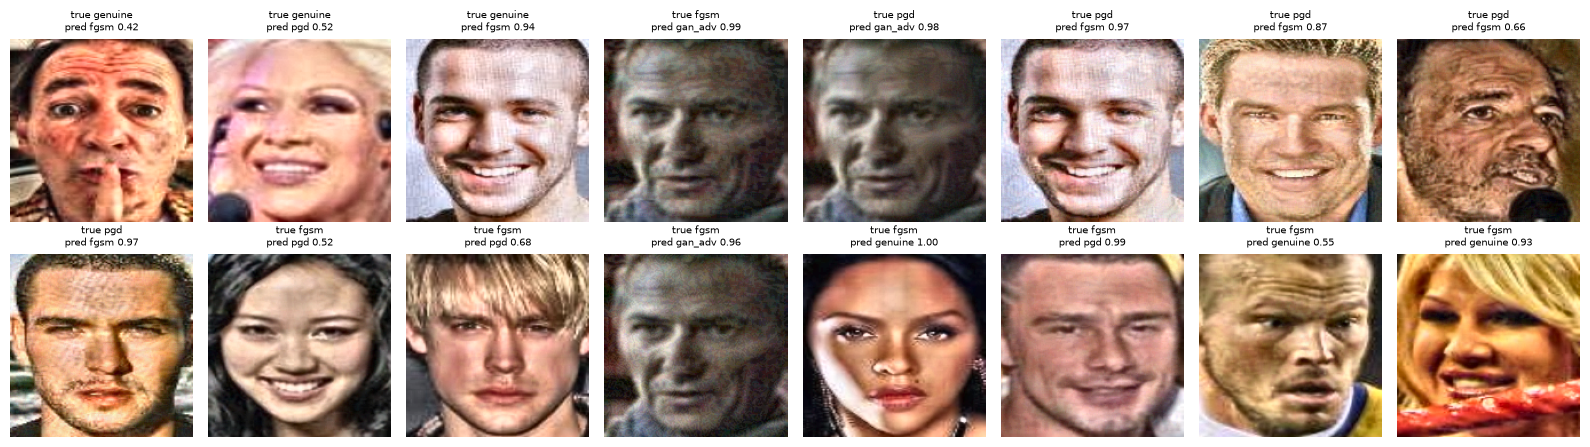

In [16]:
wrong_idx = np.where(pred_te != y_te)[0]
print(f"{len(wrong_idx)} misclassified test images")
pairs = pd.Series([f"{CLASSES[t]} -> {CLASSES[p]}" for t, p in zip(y_te[wrong_idx], pred_te[wrong_idx])]).value_counts()
print(pairs.to_string() if len(pairs) else "")
show = wrong_idx[:16]
if len(show):
    cols = 8; rws = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(2 * cols, 2.3 * rws), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for a, k in zip(axes.ravel(), show):
        a.imshow(Image.open(df_te["path"].iloc[k]))
        a.set_title(f"true {CLASSES[y_te[k]]}\npred {CLASSES[pred_te[k]]} {p_te[k].max():.2f}", fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "mistakes.png"), dpi=110); plt.show()

### 12. save everything
`celeba/blue_agent_v2/`: the model (with class names, threshold and normalisation, so the backend can load it without this notebook), `split.csv`, `history.csv`, `metrics.csv`, `detection_by_category.csv`, `shortcut_test.csv`, `v1_vs_v2.csv` and the figures - plus one zip for download.

In [17]:
MODEL_PATH = os.path.join(OUT_DIR, "blue_agent_v2_resnet18.pth")
torch.save({"arch": "resnet18", "state_dict": model.state_dict(), "classes": CLASSES,
            "threshold": THRESHOLD, "input_size": IMG_SIZE,
            "mean": MEAN.flatten().tolist(), "std": STD.flatten().tolist(),
            "best_epoch": best_epoch, "seed": SEED, "version": "v2"}, MODEL_PATH)

rep = classification_report(y_te, pred_te, labels=range(len(CLASSES)), target_names=CLASSES, output_dict=True, zero_division=0)
metrics = pd.DataFrame([{"class": c, "precision": rep[c]["precision"], "recall": rep[c]["recall"],
                         "f1": rep[c]["f1-score"], "test_images": int(rep[c]["support"])} for c in CLASSES])
metrics.loc[len(metrics)] = {"class": "OVERALL (accuracy / macro-F1 / AUC)", "precision": test_acc,
                             "recall": test_f1, "f1": auc, "test_images": len(y_te)}
metrics.round(4).to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
det.to_csv(os.path.join(OUT_DIR, "detection_by_category.csv"), index=False)
shortcut.to_csv(os.path.join(OUT_DIR, "shortcut_test.csv"), index=False)
comparison.to_csv(os.path.join(OUT_DIR, "v1_vs_v2.csv"))

zip_path = shutil.make_archive(os.path.join(BASE, "blue_agent_v2_results"), "zip", OUT_DIR)
print("saved:", sorted(os.listdir(OUT_DIR)))
print("zip:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.0f} MB)")

saved: ['blue_agent_v2_resnet18.pth', 'confusion_matrix.png', 'detection_by_category.csv', 'history.csv', 'metrics.csv', 'mistakes.png', 'roc_genuine_vs_attack.png', 'shortcut_test.csv', 'split.csv', 'training_curves.png', 'v1_vs_v2.csv']
zip: /workspace/celeba/blue_agent_v2_results.zip (43 MB)


### 13. `predict()` - one image in, a decision out
This is the function the backend and risk engine will call. It takes an image (file path or PIL image, ideally the 160x160 MTCNN crop the face-recognition pipeline already produces) and returns the 5 class probabilities, the attack probability and the decision (a class name or `suspicious`).

In [18]:
def load_blue_agent(path=MODEL_PATH, map_location=device):
    ckpt = torch.load(path, map_location=map_location, weights_only=True)   # tensors + plain values only: no pickle code execution
    net = torchvision.models.resnet18(weights=None)
    net.fc = nn.Linear(net.fc.in_features, len(ckpt["classes"]))
    net.load_state_dict(ckpt["state_dict"])
    return net.to(map_location).eval(), ckpt

@torch.no_grad()
def predict(image, net=None, ckpt=None):
    net, ckpt = (net, ckpt) if net is not None else (model.eval(), {"classes": CLASSES, "threshold": THRESHOLD, "input_size": IMG_SIZE})
    img = Image.open(image).convert("RGB") if isinstance(image, (str, os.PathLike)) else image.convert("RGB")
    s = ckpt["input_size"]
    if img.size != (s, s):
        img = img.resize((s, s), Image.BILINEAR)      # resizing weakens adversarial noise - pass 160x160 crops when possible
    probs = torch.softmax(net(to_tensor(img).unsqueeze(0).to(device)), 1)[0].cpu().numpy()
    top = int(probs.argmax())
    return {"decision": "suspicious" if probs[top] < ckpt["threshold"] else ckpt["classes"][top],
            "confidence": round(float(probs[top]), 4),
            "attack_probability": round(float(1 - probs[0]), 4),
            "probabilities": {c: round(float(p), 4) for c, p in zip(ckpt["classes"], probs)}}

# demo: reload the saved model from disk and run it on one test image per class
net, ckpt = load_blue_agent()
for cat in CLASSES:
    sample = df_te[df_te["category"] == cat]
    if len(sample):
        r = predict(sample["path"].iloc[0], net, ckpt)
        print(f"{cat:8s} -> {r['decision']:10s} conf {r['confidence']:.3f} | attack prob {r['attack_probability']:.3f}")

genuine  -> genuine    conf 0.993 | attack prob 0.007
gan      -> gan        conf 0.999 | attack prob 1.000
fgsm     -> fgsm       conf 1.000 | attack prob 1.000
pgd      -> pgd        conf 1.000 | attack prob 1.000
gan_adv  -> gan_adv    conf 0.997 | attack prob 1.000


### milestone check
- Blue Agent v2 trained on v1 + Red Agent v2 attacks with the **same person split** as v1 (no leakage)
- section 8b: **Blue v1 vs v2** on the same test images - detection per v2 technique, false alarms, full bypass rate
- `celeba/blue_agent_v2_results.zip` holds the v2 model, metrics and figures for download
- the adaptive loop: Red v1 -> Blue v1 -> Red v2 (stealthier, detector-aware) -> Blue v2. Round 3 would be a new adaptive attack against v2
- next: risk engine combines face-recognition confidence + attack probability + input quality into one risk score